# 02 · Summary moments and seasonality (plan Steps 03–04)

This notebook covers the distribution of daily spread changes, volatility clustering and seasonality. All results are a **spot proxy** (FRED/EIA spot, 2007 to 20 Oct 2026). The logic is in `src/oilrv/explore.py` and `scripts/run_analysis.py`.

In [1]:
import json
import numpy as np
import pandas as pd
from IPython.display import Image
from oilrv.config import load_config, ROOT
T, F = ROOT / 'output/tables', ROOT / 'output/figures'
read = lambda n, **k: pd.read_csv(T / n, **k)
import sys; sys.path.insert(0, str(ROOT / 'scripts'))
import run_analysis
summary = run_analysis.main(skip_slow=False)     # Parts 2-3, about 40 s

## Moments of daily spread changes ($/bbl)

In [2]:
read('02_moments.csv', index_col=0).round(4)

,n,mean,std,skew,excess_kurt,min,max,jb_p,arch_lm_p,p_gt_4sd_obs,p_gt_4sd_normal,t_df
crack321,4847.0,0.0079,1.9615,0.1071,210.4794,-50.804,52.952,0.0,0.0,0.0066,0.0001,2.2133
brent_wti,4847.0,0.0019,1.7788,-0.0421,345.9736,-54.130,52.900,0.0,0.0,0.0035,0.0001,2.5614
ho_rb,4847.0,0.0196,2.4010,0.1565,32.4683,-33.264,29.274,0.0,0.0,0.0111,0.0001,1.9796


- **Fat tails.** One day dominates the full-sample kurtosis: 20 Apr 2020, when WTI spot printed −\$36.98 (crack +\$53, Brent–WTI +\$53).
- Without that week, excess kurtosis is still about 18–33, and a fitted Student-t has ν ≈ 2–2.5.
- **Volatility clusters:** ARCH-LM p ≈ 0 for every spread.

**Implications**
- Size with the Student-t GARCH(1,1), not historical sd (Step 06).
- Keep the hard stop at |z| ≥ 4.
- Treat any statistic based on a normal distribution with caution.

In [3]:
read('02_moments_excl_apr2020.csv', index_col=0)[['std', 'skew', 'excess_kurt', 't_df']].round(3)

,std,skew,excess_kurt,t_df
crack321,1.655,-0.607,18.295,2.251
brent_wti,1.409,0.698,22.873,2.643
ho_rb,2.401,0.156,32.527,1.979


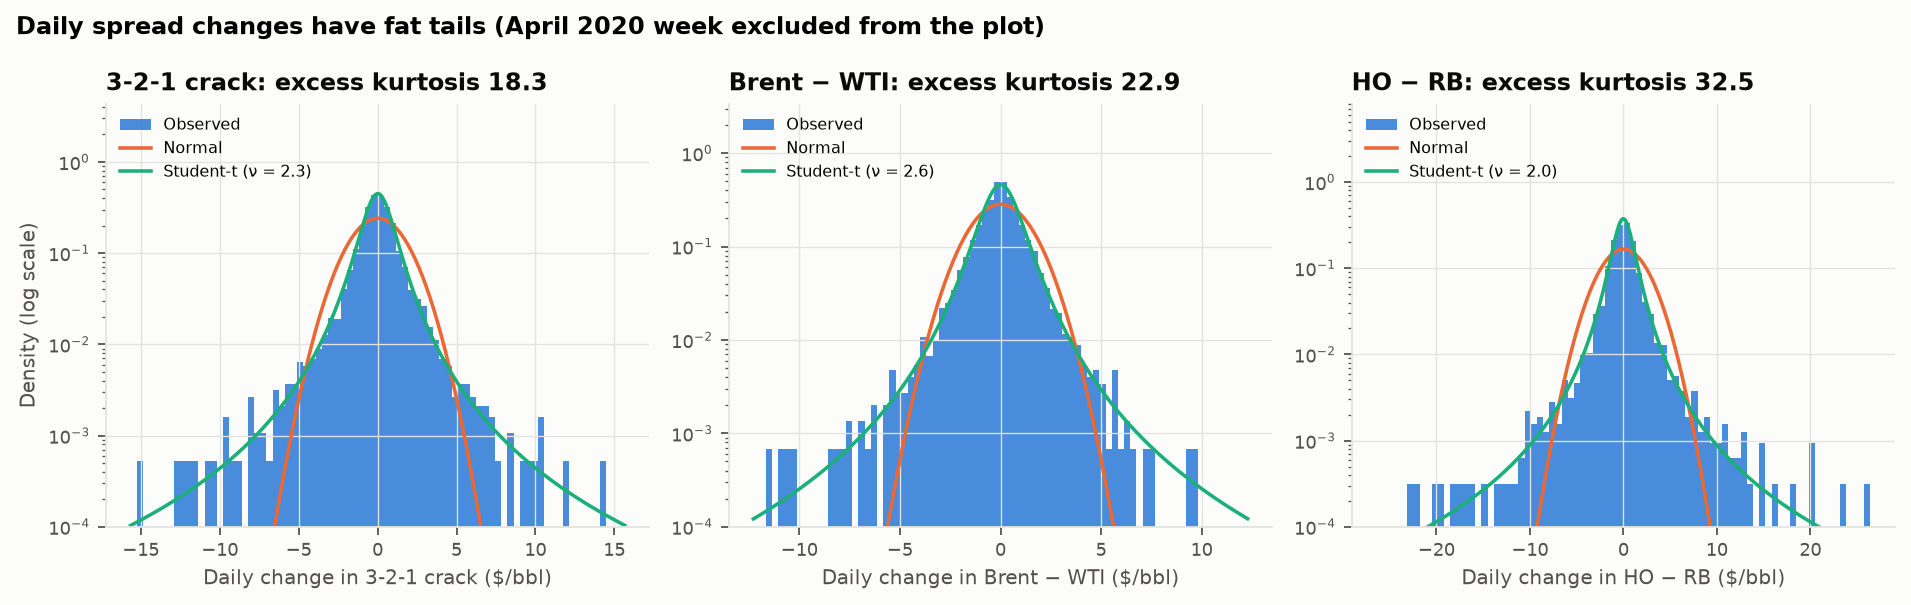

In [4]:
Image(str(F / '02_spread_change_distribution.png'))

## How far 2026 sits outside history
Here is the sd of daily changes by period:
- The crack's 2026 volatility is about 3.4 × its 2014–19 level.
- HO−RB is about 5 × in 2022 and 4 × in 2026.
- Brent–WTI spikes in 2020 (the negative-WTI day) and again in 2026.

In [5]:
m = read('02_moments_by_period.csv', index_col=[0, 1])
m['std'].unstack().round(2)

period,2007–2013,2014–2019,2020,2022,2026
series,,,,,
brent_wti,1.62,1.04,4.97,1.30,3.34
crack321,1.57,1.06,4.86,3.39,3.65
ho_rb,1.90,1.30,1.36,6.53,5.13


In [6]:
m['excess_kurt'].unstack().round(1)

period,2007–2013,2014–2019,2020,2022,2026
series,,,,,
brent_wti,7.5,1.9,108.2,2.3,11.2
crack321,21.6,8.8,105.0,3.9,3.9
ho_rb,23.4,12.3,6.0,4.6,7.7


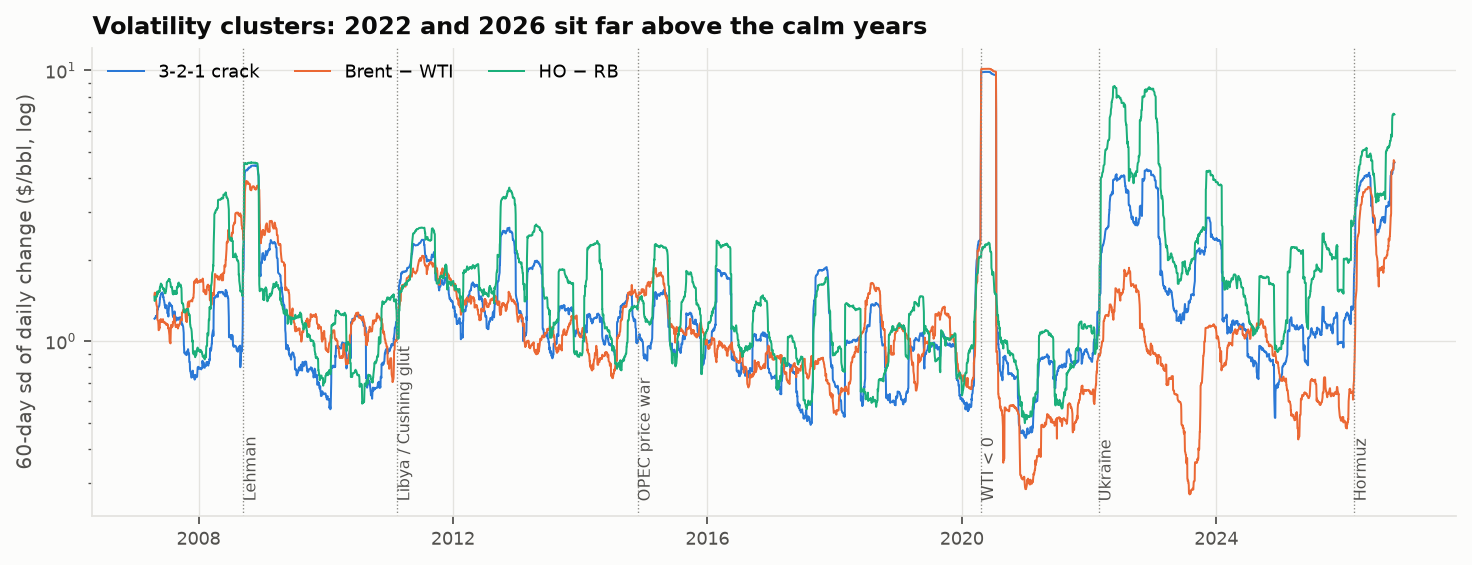

In [7]:
Image(str(F / '02_rolling_volatility.png'))

## Seasonality (monthly averages)
- **Month-of-year effect:** the monthly average minus a centred 13-month moving average, tested with Kruskal–Wallis (H0: no month effect).
- **STL strength:** the seasonal variance against the residual (Hyndman–Athanasopoulos).

In [8]:
read('02_stl_strength.csv', index_col=0).round(3)

,trend_strength,seasonal_strength,seasonal_sd,resid_sd,seasonal_peak_to_trough,kruskal_p_month
crack321,0.778,0.076,3.273,5.367,6.970,0.004
brent_wti,0.735,0.110,2.246,2.983,2.509,0.176
ho_rb,0.381,0.096,6.320,8.839,15.157,0.000


In [9]:
read('02_month_effects.csv', index_col=0).round(2)

,crack321,brent_wti,ho_rb
month,,,
1,-2.37,0.03,2.59
2,-1.04,1.32,1.73
3,-0.57,0.65,1.97
4,1.03,0.23,-2.68
5,1.78,-0.51,-4.00
6,0.97,-0.65,-4.32
7,0.56,-0.42,-4.15
8,1.08,-0.21,-2.77
9,0.64,-0.12,-0.95


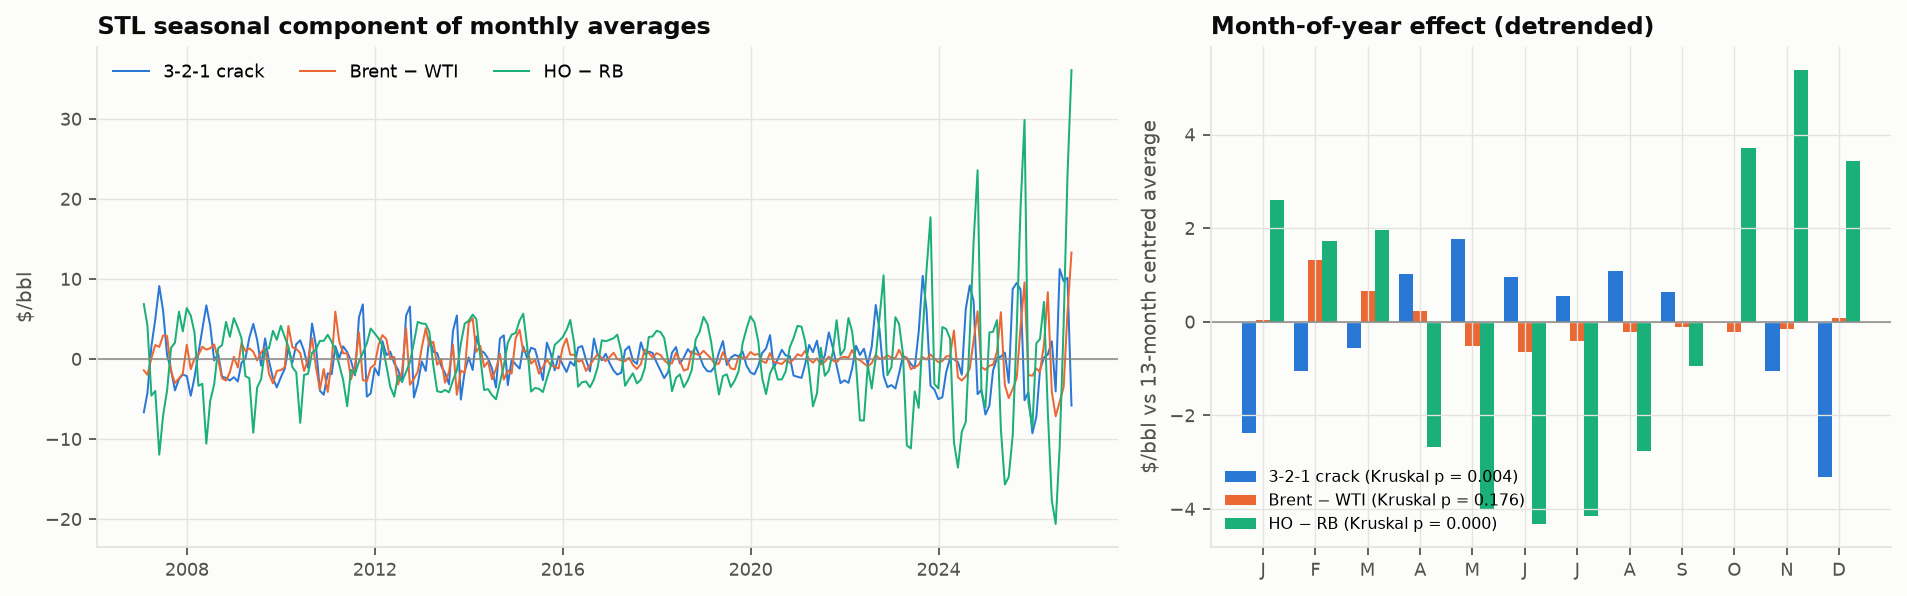

In [10]:
Image(str(F / '02_seasonality.png'))

**What this shows**
- **3-2-1 crack:** a significant month effect (p ≈ 0.004). It is strongest in Apr–Aug (driving season) and weakest in Dec–Jan. The peak-to-trough is about \$7/bbl.
- **HO − RB:** a strong month effect (p < 0.001). Diesel's premium over gasoline peaks Oct–Feb (heating season) and is lowest May–Jul, a swing of about \$15/bbl.
- **Brent − WTI:** no significant month effect (p ≈ 0.18).
- This matches the pre-registered settings: seasonal adjustment for `crack321` and `ho_rb`, none for `brent_wti`. The setting would not change whatever this test said.
- **Caveat:** STL seasonal strength is low (about 0.1) because swings within each year dwarf the seasonal pattern, and STL's seasonal component grows in 2022–26 as it absorbs some of that volatility. The model (Step 06) therefore estimates month effects inside each 756-day window only, as plain month means, not an STL fit.